# Partie 2 — Exercice 4 : Classification MNIST avec un CNN

**Objectif :** construire un réseau de neurones convolutif (CNN) pour reconnaître les chiffres manuscrits de 0 à 9.

MNIST contient 60 000 images d'entraînement et 10 000 images de test, en niveaux de gris, de taille 28 × 28 pixels.

Ce notebook suit l'énoncé fourni : chargement des données, visualisation, CNN, entraînement pendant 3 époques, évaluation, affichage de 10 erreurs, ajout de Dropout et sauvegarde du modèle.

In [1]:
import torch
from torch import nn
from torch.utils.data import DataLoader
from torchvision import datasets, transforms
import matplotlib.pyplot as plt

torch.manual_seed(42)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Appareil :", device)

transform = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize((0.1307,), (0.3081,))
])

train_dataset = datasets.MNIST(
    root="./data",
    train=True,
    download=True,
    transform=transform
)

test_dataset = datasets.MNIST(
    root="./data",
    train=False,
    download=True,
    transform=transform
)

train_loader = DataLoader(
    train_dataset, batch_size=64, shuffle=True
)

test_loader = DataLoader(
    test_dataset, batch_size=256, shuffle=False
)

images, labels = next(iter(train_loader))

print("Images :", images.shape)
print("Labels :", labels.shape)

Appareil : cpu
Images : torch.Size([64, 1, 28, 28])
Labels : torch.Size([64])


## Questions — Chargement des données

**Que représentent les quatre dimensions du tenseur `images` ?**

La forme `[64, 1, 28, 28]` signifie :

- `64` : nombre d'images dans le mini-lot ;
- `1` : nombre de canaux, car les images sont en niveaux de gris ;
- `28` : hauteur ;
- `28` : largeur.

**Pourquoi utiliser `shuffle=True` pour l'entraînement ?**

Cela mélange les données à chaque époque afin que les mini-lots ne présentent pas toujours les mêmes exemples dans le même ordre.

## 2. Visualiser quelques images

Les images ont été normalisées. Pour les afficher correctement, on annule cette normalisation avec :

`image = image × 0.3081 + 0.1307`

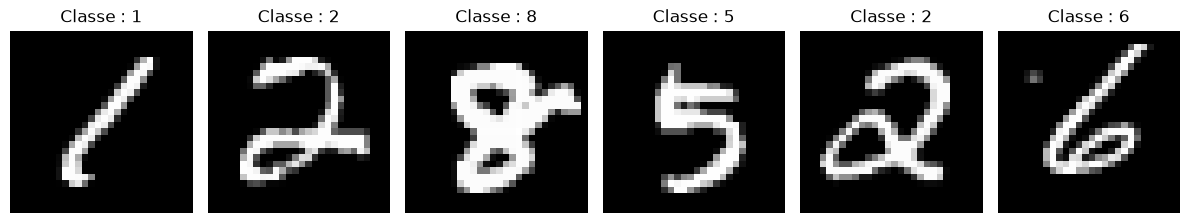

In [2]:
fig, axes = plt.subplots(1, 6, figsize=(12, 3))

for i, ax in enumerate(axes):
    # Annuler la normalisation pour l'affichage
    image = images[i, 0] * 0.3081 + 0.1307

    ax.imshow(image.numpy(), cmap="gray", vmin=0, vmax=1)
    ax.set_title(f"Classe : {labels[i].item()}")
    ax.axis("off")

plt.tight_layout()
plt.show()

## 3. Construire le CNN

Architecture demandée :

- `Conv2d(1, 16, kernel_size=3, padding=1)`
- `ReLU`
- `MaxPool2d(2)`
- `Conv2d(16, 32, kernel_size=3, padding=1)`
- `ReLU`
- `MaxPool2d(2)`
- `Flatten`
- `Linear(32 × 7 × 7, 128)`
- `ReLU`
- `Linear(128, 10)`

Après deux `MaxPool2d(2)`, la taille spatiale passe de `28 × 28` à `7 × 7`. Il reste donc `32 × 7 × 7 = 1568` valeurs avant la première couche linéaire.

In [3]:
class MNISTClassifier(nn.Module):
    def __init__(self):
        super().__init__()

        self.features = nn.Sequential(
            nn.Conv2d(
                in_channels=1,
                out_channels=16,
                kernel_size=3,
                padding=1
            ),
            nn.ReLU(),
            nn.MaxPool2d(kernel_size=2),

            nn.Conv2d(
                in_channels=16,
                out_channels=32,
                kernel_size=3,
                padding=1
            ),
            nn.ReLU(),
            nn.MaxPool2d(kernel_size=2)
        )

        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.Linear(32 * 7 * 7, 128),
            nn.ReLU(),
            nn.Linear(128, 10)
        )

    def forward(self, x):
        x = self.features(x)
        x = self.classifier(x)
        return x


model = MNISTClassifier().to(device)

# Vérifier la forme de sortie
with torch.no_grad():
    output = model(images.to(device))

assert output.shape == (images.size(0), 10)
print("Sortie :", output.shape)
print(model)

Sortie : torch.Size([64, 10])
MNISTClassifier(
  (features): Sequential(
    (0): Conv2d(1, 16, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): ReLU()
    (2): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (3): Conv2d(16, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (4): ReLU()
    (5): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  )
  (classifier): Sequential(
    (0): Flatten(start_dim=1, end_dim=-1)
    (1): Linear(in_features=1568, out_features=128, bias=True)
    (2): ReLU()
    (3): Linear(in_features=128, out_features=10, bias=True)
  )
)


### Question

**Pourquoi la première couche linéaire reçoit-elle 32 × 7 × 7 valeurs ?**

Les deux couches de convolution conservent la taille spatiale grâce à `padding=1`. Chaque `MaxPool2d(2)` divise ensuite la hauteur et la largeur par 2 :

`28 × 28 → 14 × 14 → 7 × 7`.

La deuxième convolution produit 32 canaux. On obtient donc :

`32 × 7 × 7 = 1568`.

## 4. Entraîner le réseau

L'énoncé demande **3 époques**, avec `CrossEntropyLoss` et Adam (`lr=0.001`).

In [4]:
criterion = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(model.parameters(), lr=0.001)

epochs = 3
loss_history = []

for epoch in range(epochs):
    model.train()
    total_loss = 0.0

    for images_batch, labels_batch in train_loader:
        images_batch = images_batch.to(device)
        labels_batch = labels_batch.to(device)

        # 1. Réinitialiser les gradients
        optimizer.zero_grad()

        # 2. Calculer les scores
        logits = model(images_batch)

        # 3. Calculer la perte
        loss = criterion(logits, labels_batch)

        # 4. Calculer les gradients
        loss.backward()

        # 5. Mettre à jour les paramètres
        optimizer.step()

        total_loss += loss.item() * images_batch.size(0)

    average_loss = total_loss / len(train_dataset)
    loss_history.append(average_loss)

    print(
        f"Époque {epoch + 1}/{epochs} "
        f"| Perte : {average_loss:.4f}"
    )

Époque 1/3 | Perte : 0.1679
Époque 2/3 | Perte : 0.0480
Époque 3/3 | Perte : 0.0352


## 5. Courbe de perte

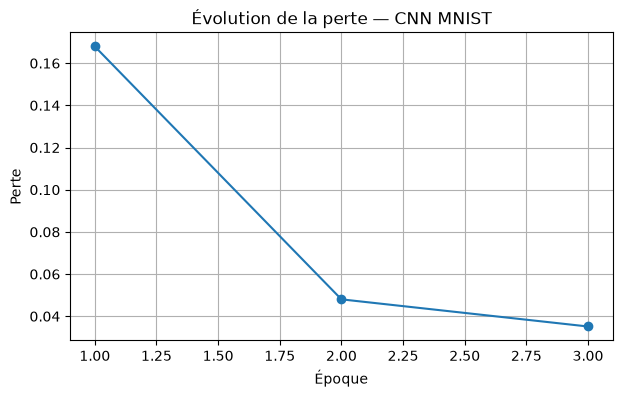

In [5]:
plt.figure(figsize=(7, 4))
plt.plot(range(1, epochs + 1), loss_history, marker="o")
plt.xlabel("Époque")
plt.ylabel("Perte")
plt.title("Évolution de la perte — CNN MNIST")
plt.grid(True)
plt.show()

## 6. Évaluer sur le jeu de test

In [6]:
model.eval()

correct = 0
total = 0

all_test_images = []
all_test_labels = []
all_test_predictions = []

with torch.no_grad():
    for images_batch, labels_batch in test_loader:
        images_batch = images_batch.to(device)
        labels_batch = labels_batch.to(device)

        logits = model(images_batch)

        # Classe ayant le score le plus élevé
        predictions = logits.argmax(dim=1)

        # Compter les bonnes prédictions
        correct += (predictions == labels_batch).sum().item()
        total += labels_batch.size(0)

        all_test_images.append(images_batch.cpu())
        all_test_labels.append(labels_batch.cpu())
        all_test_predictions.append(predictions.cpu())

accuracy = correct / total

all_test_images = torch.cat(all_test_images)
all_test_labels = torch.cat(all_test_labels)
all_test_predictions = torch.cat(all_test_predictions)

print(f"Accuracy sur le test : {accuracy:.2%}")

Accuracy sur le test : 98.90%


### Résultat attendu

L'énoncé indique qu'une accuracy **généralement supérieure à 97 %** est attendue après quelques époques, sans garantir une valeur exacte. fileciteturn25file0L30-L35

## 7. Afficher 10 images mal classées

On récupère les images pour lesquelles la classe prédite est différente de la vraie classe.

Nombre d'images mal classées : 110


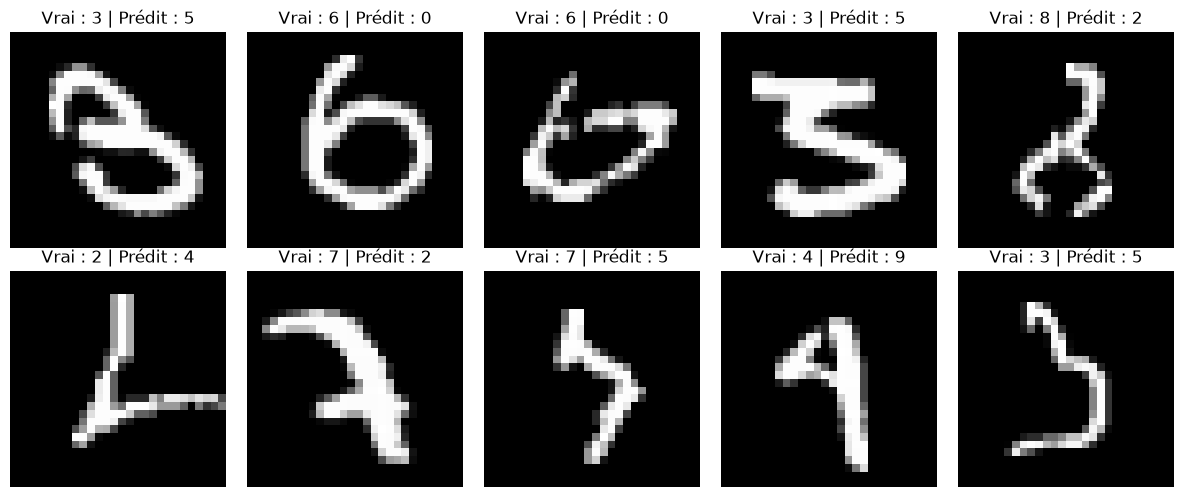

In [7]:
wrong_indices = (
    all_test_predictions != all_test_labels
).nonzero(as_tuple=True)[0]

print("Nombre d'images mal classées :", len(wrong_indices))

n_show = min(10, len(wrong_indices))

fig, axes = plt.subplots(2, 5, figsize=(12, 5))
axes = axes.flatten()

for ax in axes:
    ax.axis("off")

for i in range(n_show):
    idx = wrong_indices[i]

    # Annuler la normalisation
    image = all_test_images[idx, 0] * 0.3081 + 0.1307

    true_label = all_test_labels[idx].item()
    predicted_label = all_test_predictions[idx].item()

    axes[i].imshow(image.numpy(), cmap="gray", vmin=0, vmax=1)
    axes[i].set_title(
        f"Vrai : {true_label} | Prédit : {predicted_label}"
    )
    axes[i].axis("off")

plt.tight_layout()
plt.show()

## 8. Ajouter une couche Dropout

L'énoncé demande d'ajouter une couche Dropout **avant la dernière couche linéaire**.

Architecture modifiée :

`Linear(1568,128) → ReLU → Dropout → Linear(128,10)`

In [8]:
class MNISTClassifierDropout(nn.Module):
    def __init__(self, dropout=0.3):
        super().__init__()

        self.features = nn.Sequential(
            nn.Conv2d(1, 16, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(kernel_size=2),

            nn.Conv2d(16, 32, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(kernel_size=2)
        )

        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.Linear(32 * 7 * 7, 128),
            nn.ReLU(),
            nn.Dropout(dropout),
            nn.Linear(128, 10)
        )

    def forward(self, x):
        x = self.features(x)
        x = self.classifier(x)
        return x


model_dropout = MNISTClassifierDropout().to(device)

print(model_dropout)

MNISTClassifierDropout(
  (features): Sequential(
    (0): Conv2d(1, 16, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): ReLU()
    (2): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (3): Conv2d(16, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (4): ReLU()
    (5): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  )
  (classifier): Sequential(
    (0): Flatten(start_dim=1, end_dim=-1)
    (1): Linear(in_features=1568, out_features=128, bias=True)
    (2): ReLU()
    (3): Dropout(p=0.3, inplace=False)
    (4): Linear(in_features=128, out_features=10, bias=True)
  )
)


## 9. Sauvegarder les paramètres du modèle

L'énoncé demande exactement :

`torch.save(model.state_dict(), "mnist_cnn.pth")`

In [9]:
torch.save(model.state_dict(), "mnist_cnn.pth")

print("Paramètres sauvegardés dans : mnist_cnn.pth")

Paramètres sauvegardés dans : mnist_cnn.pth


# Résumé de l'Exercice 4

- **Dataset :** MNIST
- **Images :** 28 × 28, niveaux de gris
- **CNN :** 2 couches convolutionnelles
- **Pooling :** 2 × `MaxPool2d(2)`
- **Classification :** 10 classes
- **Loss :** `CrossEntropyLoss`
- **Optimiseur :** Adam, `lr=0.001`
- **Entraînement :** 3 époques
- **Évaluation :** Accuracy
- **Analyse :** 10 images mal classées
- **Extension :** Dropout
- **Sauvegarde :** `mnist_cnn.pth`